# Model 3 — EEGNet Results

**Input:** 8–30 Hz · 0.5–2.5 s · per-channel z-score (fit on train)
**Training:** Adam lr=1e-3 · ≤200 epochs · early stopping (patience 15) · batch 16 (Within/Transfer), 64 (Cross)
**Evaluation:** Within = LORO (3 folds) · Cross = GroupKFold-5 · Transfer = executed → imagined
**Stats:** permutation tests (Within N=200, Cross/Transfer N=1000) · BH-FDR (α=0.05)

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import os
from scipy.stats import wilcoxon

# ── Paths ─────────────────────────────────────────────────────────────────
NOTEBOOK_DIR = Path(os.path.abspath("")).resolve()
M3_RESULTS = NOTEBOOK_DIR.parent / "modeling" / "03_eegnet" / "results"
FIGURES    = NOTEBOOK_DIR / "figures"
FIGURES.mkdir(exist_ok=True)

# ── Load Model 3 CSVs ────────────────────────────────────────────────────
w1  = pd.read_csv(M3_RESULTS / "model3_eegnet_within_task1_LR.csv")
w2  = pd.read_csv(M3_RESULTS / "model3_eegnet_within_task2_FF.csv")
cx1 = pd.read_csv(M3_RESULTS / "model3_eegnet_cross_task1_LR.csv")            # per subject
cx2 = pd.read_csv(M3_RESULTS / "model3_eegnet_cross_task2_FF.csv")
cf1 = pd.read_csv(M3_RESULTS / "model3_eegnet_cross_task1_LR_perfold.csv")    # per fold (5 rows)
cf2 = pd.read_csv(M3_RESULTS / "model3_eegnet_cross_task2_FF_perfold.csv")
cx1_pooled = pd.read_csv(M3_RESULTS / "model3_eegnet_cross_task1_LR_pooled.csv").iloc[0]
cx2_pooled = pd.read_csv(M3_RESULTS / "model3_eegnet_cross_task2_FF_pooled.csv").iloc[0]
tr1 = pd.read_csv(M3_RESULTS / "model3_eegnet_transfer_task1_LR.csv")
tr2 = pd.read_csv(M3_RESULTS / "model3_eegnet_transfer_task2_FF.csv")

# Cross: per-subject FDR from cross_subject_permtest.py
SIG = pd.read_csv(NOTEBOOK_DIR / "cross_subject_persubject_significance.csv")   # from cross_subject_permtest.py

def cross_fdr(variant, task):
    return SIG[(SIG.variant == variant) & (SIG.task == task)][["subject", "fdr_sig"]]
cx1 = cx1.merge(cross_fdr("M3-EEGNet", "T1").rename(columns={"fdr_sig": "eegnet_fdr_sig"}), on="subject")
cx2 = cx2.merge(cross_fdr("M3-EEGNet", "T2").rename(columns={"fdr_sig": "eegnet_fdr_sig"}), on="subject")

# ── Summary table ──────────────────────────────────────────────────────────
# (df, label, FDR column or pooled row)
EXPS = [
    (w1,  "Within T1 (L/R fist)",     "eegnet_perm_pvalue_fdr_sig"),
    (w2,  "Within T2 (Fists/Feet)",   "eegnet_perm_pvalue_fdr_sig"),
    (cx1, "Cross T1 (L/R fist)",      cx1_pooled),
    (cx2, "Cross T2 (Fists/Feet)",    cx2_pooled),
    (tr1, "Transfer T1 (L/R fist)",   "eegnet_perm_fdr_sig"),
    (tr2, "Transfer T2 (Fists/Feet)", "eegnet_perm_fdr_sig"),
]
rows = []
for df, label, sig in EXPS:
    if isinstance(sig, str):
        m = {k: df[f"eegnet_{k}"].mean() for k in ("acc", "bal_acc", "auc", "kappa", "sensitivity", "specificity")}
        _, group_p = wilcoxon(df["eegnet_acc"] - 0.5)
        fdr = f"{int(df[sig].sum())}/106"
    else:
        m = {k: sig[k] for k in ("acc", "bal_acc", "auc", "kappa", "sensitivity", "specificity")}
        group_p = sig["perm_pvalue"]
        fdr = f"{int(df['eegnet_fdr_sig'].sum())}/106"
    rows.append({"Experiment": label,
                 "Acc": round(m["acc"], 3), "Bal.Acc": round(m["bal_acc"], 3),
                 "AUC": round(m["auc"], 3), "Kappa": round(m["kappa"], 3),
                 "Sensitivity": round(m["sensitivity"], 3), "Specificity": round(m["specificity"], 3),
                 "Group p": f"{group_p:.2g}", "FDR sig": fdr})

summary = pd.DataFrame(rows).set_index("Experiment")
print("=" * 90)
print("Model 3 (EEGNet) — Summary Statistics")
print("(Within/Transfer: mean across 106 subjects · Cross: mean across 5 GroupKFold folds)")
print("(Group p: Wilcoxon vs 0.5 for Within/Transfer · pooled permutation test for Cross)")
print("=" * 90)
display(summary)


Model 3 (EEGNet) — Summary Statistics
(Within/Transfer: mean across 106 subjects · Cross: mean across 5 GroupKFold folds)
(Group p: Wilcoxon vs 0.5 for Within/Transfer · pooled permutation test for Cross)


,Acc,Bal.Acc,AUC,Kappa,Sensitivity,Specificity,Group p,FDR sig
Experiment,,,,,,,,
Within T1 (L/R fist),0.509,0.504,0.521,0.009,0.441,0.568,0.18,0/106
Within T2 (Fists/Feet),0.539,0.532,0.579,0.065,0.510,0.555,2.2e-06,16/106
Cross T1 (L/R fist),0.640,0.640,0.694,0.279,0.596,0.682,0.001,39/106
Cross T2 (Fists/Feet),0.629,0.630,0.680,0.260,0.518,0.741,0.001,39/106
Transfer T1 (L/R fist),0.514,0.512,0.542,0.024,0.391,0.634,0.027,0/106
Transfer T2 (Fists/Feet),0.549,0.549,0.622,0.098,0.468,0.630,0.00012,13/106


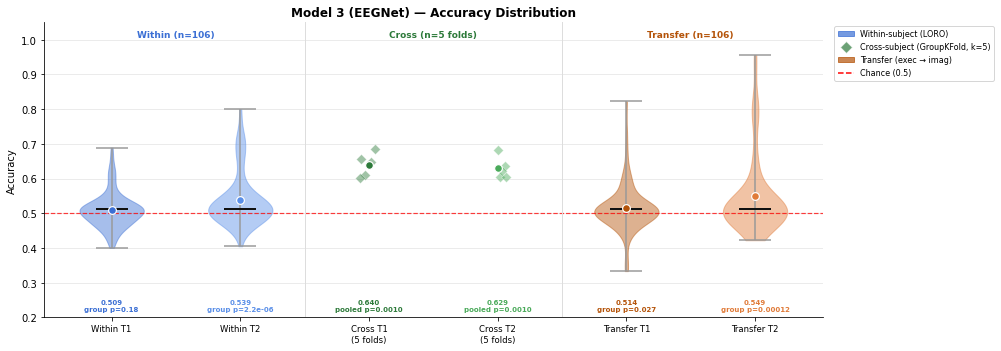

Saved model3_accuracy_violin.png


In [2]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# Cross: jittered folds; Within/Transfer: violins. 5th element: group-level p-value.
vdata = [
    (w1["eegnet_acc"].values,   "Within T1",              "#3b6fd4", False, None),
    (w2["eegnet_acc"].values,   "Within T2",              "#5a8fe8", False, None),
    (cf1["eegnet_acc"].values,  "Cross T1\n(5 folds)",    "#2d7a3a", True,  float(cx1_pooled["perm_pvalue"])),
    (cf2["eegnet_acc"].values,  "Cross T2\n(5 folds)",    "#4aaa5a", True,  float(cx2_pooled["perm_pvalue"])),
    (tr1["eegnet_acc"].values,  "Transfer T1",            "#b45309", False, None),
    (tr2["eegnet_acc"].values,  "Transfer T2",            "#e07b39", False, None),
]

fig, ax = plt.subplots(figsize=(14, 5))
positions = np.arange(1, len(vdata) + 1)

violin_positions = [p for p, (_, _, _, is_fold, _) in zip(positions, vdata) if not is_fold]
violin_data       = [d[0] for d in vdata if not d[3]]
violin_colors     = [d[2] for d in vdata if not d[3]]

parts = ax.violinplot(violin_data, positions=violin_positions, showmedians=True, showextrema=True)
for pc, color in zip(parts["bodies"], violin_colors):
    pc.set_facecolor(color); pc.set_alpha(0.45); pc.set_edgecolor(color)
parts["cmedians"].set_color("#111"); parts["cmedians"].set_linewidth(2)
for key in ("cmaxes", "cmins", "cbars"):
    parts[key].set_color("#999")

rng = np.random.default_rng(0)
for pos, (vals, label, color, is_fold, pooled_p) in zip(positions, vdata):
    if is_fold:
        jitter = rng.uniform(-0.07, 0.07, size=len(vals))
        ax.scatter(np.full(len(vals), pos) + jitter, vals, color=color, alpha=0.45, s=50,
                   marker="D", edgecolors="white", linewidth=0.7, zorder=3)

for i, (vals, _, color, is_fold, pooled_p) in enumerate(vdata):
    ax.scatter(positions[i], vals.mean(), color=color, s=60, zorder=5,
               edgecolors="white", linewidth=1.2)
    if pooled_p is not None:
        sig_txt = f"pooled p={pooled_p:.4f}"
    else:
        _, group_p = wilcoxon(vals - 0.5)
        sig_txt = f"group p={group_p:.2g}"
    ax.text(positions[i], 0.215, f"{vals.mean():.3f}\n{sig_txt}", ha="center", va="bottom", fontsize=7, color=color, fontweight="bold")

ax.axhline(0.5, color="red", linestyle="--", linewidth=1.2, alpha=0.75)

for sep in [2.5, 4.5]:
    ax.axvline(sep, color="#ddd", linewidth=1)
for xp, lbl, col in [(1.5,"Within (n=106)","#3b6fd4"),(3.5,"Cross (n=5 folds)","#2d7a3a"),(5.5,"Transfer (n=106)","#b45309")]:
    ax.text(xp, 0.95, lbl, ha="center", transform=ax.get_xaxis_transform(),
            fontsize=9, color=col, fontweight="bold")

ax.set_xticks(positions)
ax.set_xticklabels([d[1] for d in vdata], fontsize=8.5)
ax.set_ylabel("Accuracy", fontsize=10)
ax.set_ylim(0.2, 1.05)
ax.set_title("Model 3 (EEGNet) — Accuracy Distribution", fontsize=12, fontweight="bold")
ax.yaxis.grid(True, alpha=0.3); ax.set_axisbelow(True)
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
legend_handles = [
    mpatches.Patch(color="#3b6fd4", alpha=0.7, label="Within-subject (LORO)"),
    plt.Line2D([0],[0], marker="D", color="w", markerfacecolor="#2d7a3a", markersize=8, alpha=0.7, label="Cross-subject (GroupKFold, k=5)"),
    mpatches.Patch(color="#b45309", alpha=0.7, label="Transfer (exec → imag)"),
    plt.Line2D([0],[0], color="red",  linestyle="--", label="Chance (0.5)"),
]
ax.legend(handles=legend_handles, fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1), frameon=True)
plt.tight_layout()
plt.savefig(FIGURES / "model3_accuracy_violin.png", dpi=150, bbox_inches="tight")
plt.show(); print("Saved model3_accuracy_violin.png")

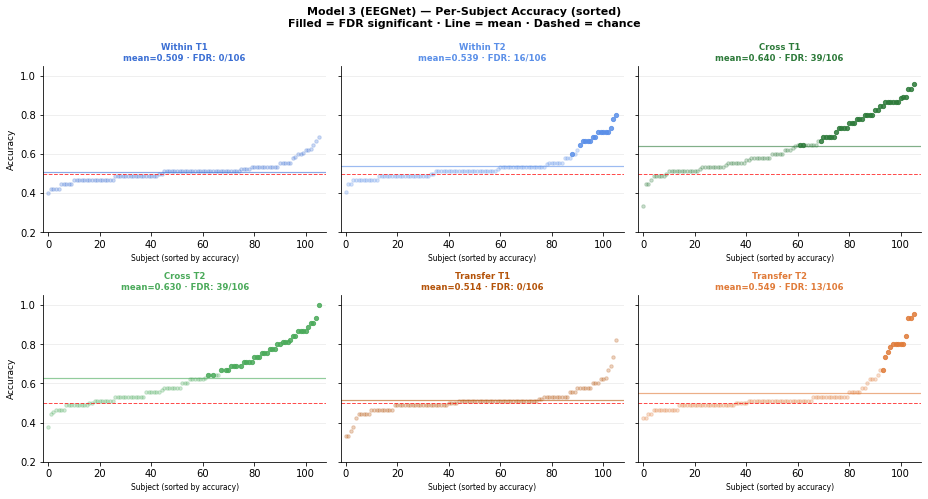

Saved model3_accuracy_dotplot.png


In [3]:
# Per-subject accuracy, sorted
dot_data = [
    (w1["eegnet_acc"].values,  w1["eegnet_perm_pvalue_fdr_sig"].values, None,                       "Within T1",   "#3b6fd4"),
    (w2["eegnet_acc"].values,  w2["eegnet_perm_pvalue_fdr_sig"].values, None,                       "Within T2",   "#5a8fe8"),
    (cx1["eegnet_acc"].values, cx1["eegnet_fdr_sig"].values.astype(int), None,             "Cross T1",    "#2d7a3a"),
    (cx2["eegnet_acc"].values, cx2["eegnet_fdr_sig"].values.astype(int), None,             "Cross T2",    "#4aaa5a"),
    (tr1["eegnet_acc"].values, tr1["eegnet_perm_fdr_sig"].values,      None,                       "Transfer T1", "#b45309"),
    (tr2["eegnet_acc"].values, tr2["eegnet_perm_fdr_sig"].values,      None,                       "Transfer T2", "#e07b39"),
]

fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharey=True)
axes = axes.flatten()

for ax, (vals, sig, _, label, color) in zip(axes, dot_data):
    order  = np.argsort(vals)
    vals_s = vals[order]
    x = np.arange(len(vals_s))
    sig_s = sig[order]
    ax.scatter(x[sig_s == 0], vals_s[sig_s == 0], color=color, alpha=0.25, s=12)
    ax.scatter(x[sig_s == 1], vals_s[sig_s == 1], color=color, alpha=0.85, s=18, label="FDR sig.")
    fdr_txt = f" · FDR: {int(sig.sum())}/106"
    ax.axhline(0.5,         color="red",  linestyle="--", linewidth=1, alpha=0.7)
    ax.axhline(vals.mean(), color=color,  linestyle="-",  linewidth=1.2, alpha=0.6)
    ax.set_title(f"{label}\nmean={vals.mean():.3f}{fdr_txt}",
                 fontsize=8.5, fontweight="bold", color=color)
    ax.set_xlabel("Subject (sorted by accuracy)", fontsize=7.5)
    ax.set_xlim(-2, 108); ax.set_ylim(0.2, 1.05)
    ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
    ax.yaxis.grid(True, alpha=0.25); ax.set_axisbelow(True)

axes[0].set_ylabel("Accuracy", fontsize=9)
axes[3].set_ylabel("Accuracy", fontsize=9)
fig.suptitle("Model 3 (EEGNet) — Per-Subject Accuracy (sorted)\n"
             "Filled = FDR significant · Line = mean · Dashed = chance",
             fontsize=11, fontweight="bold")
plt.tight_layout()
plt.savefig(FIGURES / "model3_accuracy_dotplot.png", dpi=150, bbox_inches="tight")
plt.show(); print("Saved model3_accuracy_dotplot.png")

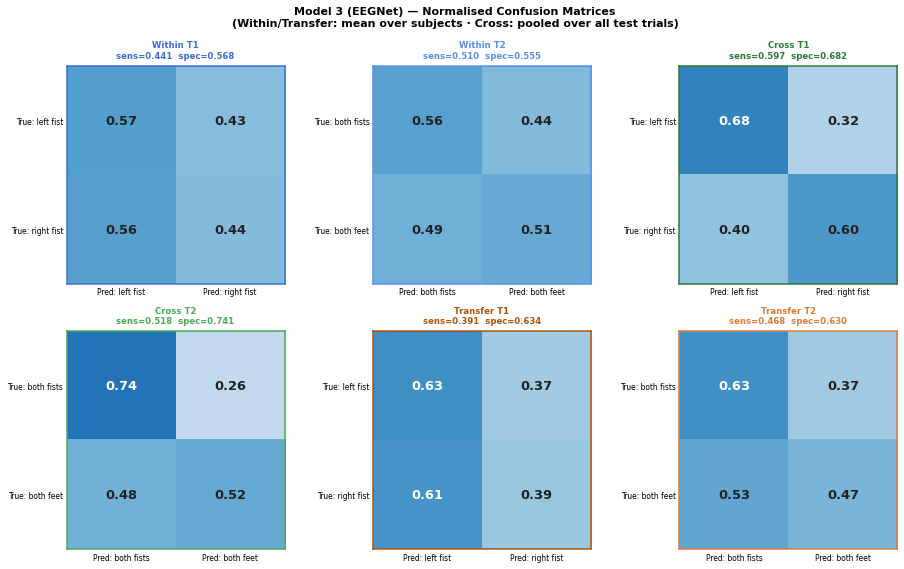

Saved model3_confusion_matrices.png


In [4]:
# Normalised confusion matrices (Cross: pooled values)
conf_data = [
    (w1,  None,       "Within T1",   "#3b6fd4", ("left fist", "right fist")),
    (w2,  None,       "Within T2",   "#5a8fe8", ("both fists", "both feet")),
    (cx1, cx1_pooled, "Cross T1",    "#2d7a3a", ("left fist", "right fist")),
    (cx2, cx2_pooled, "Cross T2",    "#4aaa5a", ("both fists", "both feet")),
    (tr1, None,       "Transfer T1", "#b45309", ("left fist", "right fist")),
    (tr2, None,       "Transfer T2", "#e07b39", ("both fists", "both feet")),
]

fig, axes = plt.subplots(2, 3, figsize=(13, 8))
axes = axes.flatten()
for ax, (df, pooled_row, label, color, (cls0, cls1)) in zip(axes, conf_data):
    if pooled_row is not None:
        sens, spec = pooled_row["sensitivity"], pooled_row["specificity"]
    else:
        sens, spec = df["eegnet_sensitivity"].mean(), df["eegnet_specificity"].mean()
    cm = np.array([[spec, 1 - spec], [1 - sens, sens]])
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    for r in range(2):
        for c in range(2):
            ax.text(c, r, f"{cm[r, c]:.2f}", ha="center", va="center", fontsize=13, fontweight="bold",
                    color="white" if cm[r, c] > 0.6 else "#222")
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels([f"Pred: {cls0}", f"Pred: {cls1}"], fontsize=7.5)
    ax.set_yticklabels([f"True: {cls0}", f"True: {cls1}"], fontsize=7.5)
    ax.set_title(f"{label}\nsens={sens:.3f}  spec={spec:.3f}", fontsize=8.5, fontweight="bold", color=color, pad=8)
    ax.tick_params(length=0)
    for spine in ax.spines.values():
        spine.set_edgecolor(color); spine.set_linewidth(1.5)

fig.suptitle("Model 3 (EEGNet) — Normalised Confusion Matrices\n"
             "(Within/Transfer: mean over subjects · Cross: pooled over all test trials)",
             fontsize=11, fontweight="bold")
plt.tight_layout()
plt.savefig(FIGURES / "model3_confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show(); print("Saved model3_confusion_matrices.png")
